# Lab 19.2: Which Source Did the Model Use?

Chapter 19 of *Explainable AI in Practice*. We give GPT-2 small (124M parameters, CPU) a context of six sentences from an invented parcel firm's policy, ask a question, and measure how much each sentence contributes to the answer by removing it (leave one out) and by fitting a sparse linear surrogate to random subsets of sentences (in the spirit of ContextCite, Cohen-Wang et al., 2024). Then we compare the attributions with a printed citation, and try a question whose answer the model knows without the context.

Environment: the language-model environment in `env/requirements-llm.txt` (torch 2.6.0, transformers 4.57.6, scikit-learn 1.7.2). The first run downloads GPT-2 small (about 500 MB) from the Hugging Face hub unless it is already cached. Nothing here needs an API key.

In [1]:
import numpy as np, torch, matplotlib.pyplot as plt
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
from sklearn.linear_model import Lasso
torch.manual_seed(0)
tok = GPT2TokenizerFast.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2").eval()
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 124439808


## 1. The context, the question and the response

S2 and S6 state the same refund rule in different words. The response we explain is fixed: " 30 days". We score it by its log probability under the model, given a context made of the sentences that are kept.

In [2]:
SOURCES = ["Northway Parcels delivers on weekdays between 8 am and 6 pm.",
           "If a parcel is lost, customers can claim a refund within 30 days.",
           "Refund claims must include the tracking number.",
           "The Lakeside depot is closed on public holidays.",
           "Customers who miss a delivery can collect the parcel from the depot.",
           "A refund for a lost parcel can be requested up to 30 days after the expected delivery date."]
QUESTION = "Question: How many days do customers have to claim a refund for a lost parcel?\nAnswer: Customers have"
RESPONSE = " 30 days"

def logp(mask, sources=SOURCES, question=QUESTION, response=RESPONSE):
    ctx = " ".join(s for s, k in zip(sources, mask) if k)
    ids = tok("Context: " + ctx + "\n" + question, return_tensors="pt").input_ids
    r = tok(response, return_tensors="pt").input_ids
    x = torch.cat([ids, r], 1)
    with torch.no_grad():
        lp = torch.log_softmax(model(x).logits[0, :-1], -1)
    n = r.shape[1]
    return float(lp[-n:].gather(1, x[0, -n:, None]).sum())

k = len(SOURCES)
full = logp([1] * k)
print(f"log p(response | full context) = {full:.3f}   (p = {np.exp(full):.3f})")

log p(response | full context) = -2.867   (p = 0.057)


**Checkpoint 1:** the full-context log probability is about -2.87 (probability about 0.057).

## 2. Leave one out

In [3]:
loo = [full - logp([0 if j == i else 1 for j in range(k)]) for i in range(k)]
for i, v in enumerate(loo):
    print(f"S{i+1}: drop {v:+.3f}   {SOURCES[i]}")
both = full - logp([0 if j in (1, 5) else 1 for j in range(k)])
none = full - logp([0] * k)
print(f"\nremove S2 and S6 together: drop {both:.3f}")
print(f"remove all six sentences:  drop {none:.3f}")

S1: drop -0.284   Northway Parcels delivers on weekdays between 8 am and 6 pm.
S2: drop +0.241   If a parcel is lost, customers can claim a refund within 30 days.
S3: drop +0.018   Refund claims must include the tracking number.
S4: drop -0.015   The Lakeside depot is closed on public holidays.
S5: drop +0.039   Customers who miss a delivery can collect the parcel from the depot.
S6: drop +0.214   A refund for a lost parcel can be requested up to 30 days after the expected delivery date.

remove S2 and S6 together: drop 0.652
remove all six sentences:  drop 1.423


**Checkpoint 2:** S2 drops about 0.24 and S6 about 0.21; removing both drops about 0.65; removing everything drops about 1.42. Leave one out understates each of the redundant pair.

## 3. Random ablations and a sparse linear surrogate

We sample 64 random keep/remove masks, score each, and fit a Lasso regression (alpha 0.01) from masks to log probability. ContextCite fits the logit of the probability instead; with probabilities this small the two are close.

In [4]:
X = np.random.default_rng(0).integers(0, 2, (64, k))
y = np.array([logp(list(m)) for m in X])
sur = Lasso(alpha=0.01).fit(X, y)
w = sur.coef_
for i in range(k):
    print(f"S{i+1}: leave-one-out {loo[i]:+.3f}   surrogate {w[i]:+.3f}")

# How well does the surrogate predict held-out ablations?
Xt = np.random.default_rng(1).integers(0, 2, (32, k))
yt = np.array([logp(list(m)) for m in Xt])
from scipy.stats import spearmanr
print("\nSpearman correlation, predicted vs actual on 32 new ablations:", round(spearmanr(sur.predict(Xt), yt).correlation, 3))

S1: leave-one-out -0.284   surrogate -0.102
S2: leave-one-out +0.241   surrogate +0.648
S3: leave-one-out +0.018   surrogate +0.027
S4: leave-one-out -0.015   surrogate +0.000
S5: leave-one-out +0.039   surrogate +0.025
S6: leave-one-out +0.214   surrogate +0.273



Spearman correlation, predicted vs actual on 32 new ablations: 0.935


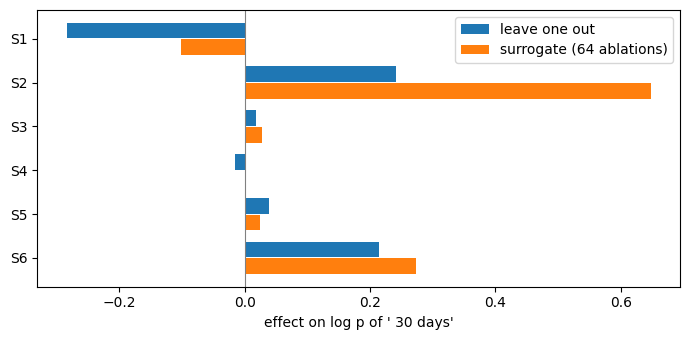

In [5]:
yy = np.arange(k)[::-1]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(yy + 0.19, loo, height=0.36, label="leave one out")
ax.barh(yy - 0.19, w, height=0.36, label="surrogate (64 ablations)")
ax.set_yticks(yy); ax.set_yticklabels([f"S{i+1}" for i in range(k)])
ax.axvline(0, color="gray", lw=0.8); ax.legend(); ax.set_xlabel("effect on log p of ' 30 days'")
plt.tight_layout(); plt.show()

**Checkpoint 3:** the surrogate gives S2 about 0.65 and S6 about 0.27; every other source is below 0.03 in absolute value except S1 (about -0.10). The rank correlation on new ablations is printed above; the surrogate is useful only if it is clearly positive.

## 4. Check a printed citation

Suppose the application printed this answer: "Customers have 30 days [S3]." Is the citation faithful?

In [6]:
printed = 2   # index of S3
top = int(np.argmax(w))
print("printed citation: S3, surrogate weight", round(w[printed], 3))
print("highest-weight source: S%d, weight %.3f" % (top + 1, w[top]))
print("verdict:", "faithful" if top == printed else "the printed citation did not drive the answer")

printed citation: S3, surrogate weight 0.027
highest-weight source: S2, weight 0.648
verdict: the printed citation did not drive the answer


## 5. A question the model can answer without the context

Now ask about something GPT-2 has seen many times in training. If removing all sources barely changes the answer's probability, citations to those sources would be decorative.

In [7]:
Q2 = "Question: What is the capital of France?\nAnswer: The capital of France is"
R2 = " Paris"
SRC2 = SOURCES[:5] + ["Paris is the capital of France and its largest city."]
f2 = logp([1] * 6, SRC2, Q2, R2)
drop_all = f2 - logp([0] * 6, SRC2, Q2, R2)
drop_s6 = f2 - logp([1, 1, 1, 1, 1, 0], SRC2, Q2, R2)
print(f"log p(' Paris' | full context) = {f2:.3f}")
print(f"drop when the Paris sentence is removed: {drop_s6:.3f}")
print(f"drop when all sentences are removed:    {drop_all:.3f}")
print(f"\nprobability with no context at all: Paris {np.exp(f2 - drop_all):.3f}   vs   '30 days' {np.exp(full - none):.3f}")

log p(' Paris' | full context) = -0.684
drop when the Paris sentence is removed: 2.143
drop when all sentences are removed:    1.794

probability with no context at all: Paris 0.084   vs   '30 days' 0.014


**Checkpoint 4:** with GPT-2 small, removing the Paris sentence still lowers the log probability by about 2.1, and removing everything by about 1.8: this small model leans heavily on its context even for a famous fact. Without any context it still gives " Paris" a probability of about 0.08, against about 0.01 for " 30 days". A larger model would know the fact far better, and the drop could shrink toward zero; that is the situation in which citations become decorative. Write down whether, for GPT-2 small, a citation to the Paris sentence would be faithful, correct, both or neither, and what you would expect from a large model.

## Questions

1. Why does leave one out understate S2 and S6? What would happen to a "top source" citation rule built on leave one out?
2. The surrogate gives S1 (delivery hours) a negative weight. What does a negative attribution mean here, and should a citation system ever show it?
3. For the Paris question, what does the size of the "remove all" drop tell you about post-rationalization?
4. What would you need from a hosted model's interface to run this test on a production assistant?